<a href="https://colab.research.google.com/github/Nahupazoss/TPI-Analisis-de-Datos-Grupo4/blob/main/notebooks/TPI_Analisis_de_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Integrador (TPI) — Análisis de Abandono de Clientes (Telco Customer Churn)
**Materia:** Introducción al Análisis de Datos  
**Grupo:** 4  

---

## 1. Fundamentos y Definición del Problema de Negocio

### Problema de Negocio
Una empresa de telecomunicaciones enfrenta una pérdida constante de clientes que deciden cancelar su suscripción (**Churn**). Dado que adquirir un cliente nuevo resulta significativamente más costoso que retener a uno existente, el objetivo de este proyecto es analizar el comportamiento histórico de los clientes para identificar los factores principales asociados a la cancelación y proponer acciones de retención basadas en datos.

### Variable de Interés Principal (Target)
* **`Churn`**: Variable categórica binaria (`Yes` / `No`) que indica si el cliente canceló o no el servicio durante el último mes.

### Hipótesis Analíticas
1. **Hipótesis de Tipo de Contrato:** Los clientes con contratos mes a mes (*Month-to-month*) presentan una tasa de cancelación (`Churn`) sustancialmente mayor que aquellos con contratos anuales o bianuales.
2. **Hipótesis de Antigüedad (`tenure`):** Los clientes recientes (con baja antigüedad en meses) muestran mayor propensión al abandono que los clientes consolidados.
3. **Hipótesis de Facturación Mensual (`MonthlyCharges`):** Los clientes con cargos mensuales elevados tienen mayor probabilidad de cancelar el servicio.

In [1]:
# Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Carga del dataset desde URL pública confiable (garantiza reproducibilidad en Colab)
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(f"Dataset cargado exitosamente: {df.shape[0]} registros (filas) y {df.shape[1]} variables (columnas).")
display(df.head())

Dataset cargado exitosamente: 7043 registros (filas) y 21 variables (columnas).


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Inspección de estructura, valores no nulos y tipos de datos (dtypes) asignados por defecto
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Clasificación del Dataset y Relevamiento de Variables

### Clasificación según su Estructura
El dataset **Telco Customer Churn** corresponde a **datos estructurados**, ya que se organiza en un formato tabular bidimensional (filas y columnas) con un esquema fijo, donde cada fila representa a un cliente único y cada columna corresponde a un atributo específico con un formato predefinido.

### Contraste: Clasificación Teórica vs. Tipos en Pandas (`dtypes`)
Al ejecutar `df.info()`, observamos cómo Pandas interpreta inicialmente cada columna y detectamos una inconsistencia clave en `TotalCharges`:

| Variable | Descripción | Clasificación Teórica | `dtype` en Pandas (Inicial) | Observación / Acción Requerida |
| :--- | :--- | :--- | :--- | :--- |
| `customerID` | Identificador único del cliente | Cualitativa Nominal (ID) | `object` | Irrelevante para análisis estadístico (se eliminará). |
| `gender` | Género del cliente (`Male`, `Female`) | Cualitativa Nominal | `object` | Correcto. |
| `SeniorCitizen` | Indica si es adulto mayor (`0` = No, `1` = Sí) | Cualitativa Nominal (Binaria codificada) | `int64` | Aunque Pandas la lee como entero, conceptualmente es una categoría binaria. |
| `Partner` / `Dependents` | Si tiene pareja / personas a cargo (`Yes`/`No`) | Cualitativa Nominal | `object` | Correcto. |
| `tenure` | Meses de permanencia en la empresa | Cuantitativa Discreta | `int64` | Correcto (conteo entero de meses). |
| `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, etc. | Servicios contratados por el cliente | Cualitativa Nominal | `object` | Correcto. |
| `Contract` | Tipo de contrato (`Month-to-month`, `One year`, `Two year`) | Cualitativa Ordinal | `object` | Posee una jerarquía natural de duración temporal. |
| `PaperlessBilling` / `PaymentMethod` | Facturación electrónica y método de pago | Cualitativa Nominal | `object` | Correcto. |
| `MonthlyCharges` | Cargo mensual facturado al cliente (USD) | Cuantitativa Continua | `float64` | Correcto. |
| `TotalCharges` | Cargo total acumulado por el cliente (USD) | Cuantitativa Continua | **`object` (Error)** | **Anomalía:** Pandas la lee como texto debido a espacios en blanco (`" "`). Debe convertirse a `float64`. |
| `Churn` | Si el cliente abandonó el servicio (`Yes`/`No`) | Cualitativa Nominal (Target) | `object` | Variable objetivo principal. |

## 3. Limpieza y Calidad de Datos

### Tratamiento de Cadenas Anómalas, Nulos y Tipos de Datos
Al inspeccionar los tipos de datos (`dtypes`), detectamos que la variable `TotalCharges` fue importada como texto (`object`). Esto ocurre porque existen registros con espacios en blanco (`" "`). A continuación, detectamos esos casos, convertimos la columna a formato numérico (`float64`), imputamos los valores faltantes de forma fundamentada y eliminamos la columna identificadora `customerID` por no aportar valor estadístico.

In [3]:
# 1. Detección de cadenas anómalas (espacios vacíos) en TotalCharges
espacios_vacios = df[df['TotalCharges'].str.strip() == '']
print(f"Registros con espacios vacíos en TotalCharges: {len(espacios_vacios)}")
display(espacios_vacios[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

# 2. Conversión formal de TotalCharges a tipo numérico (float64)
# errors='coerce' convierte los espacios vacíos en NaN (nulos reales)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 3. Imputación fundamentada: como todos estos clientes tienen tenure == 0 (clientes nuevos
# que aún no cerraron su primer ciclo de facturación), imputamos TotalCharges con 0.0
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)

# 4. Eliminación de atributos irrelevantes para el análisis (customerID)
df.drop(columns=['customerID'], inplace=True)

# 5. Verificación final de calidad de datos
print(f"\nFilas duplicadas: {df.duplicated().sum()}")
print(f"Total de valores nulos tras limpieza: {df.isna().sum().sum()}")
print(f"Nuevo tipo de dato de TotalCharges: {df['TotalCharges'].dtype}")

Registros con espacios vacíos en TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



Filas duplicadas: 22
Total de valores nulos tras limpieza: 0
Nuevo tipo de dato de TotalCharges: float64


--- Análisis de Outliers (Método IQR) ---
tenure: Q1=9.00, Q3=55.00, IQR=46.00 | Outliers detectados: 0
MonthlyCharges: Q1=35.50, Q3=89.85, IQR=54.35 | Outliers detectados: 0
TotalCharges: Q1=398.55, Q3=3786.60, IQR=3388.05 | Outliers detectados: 0


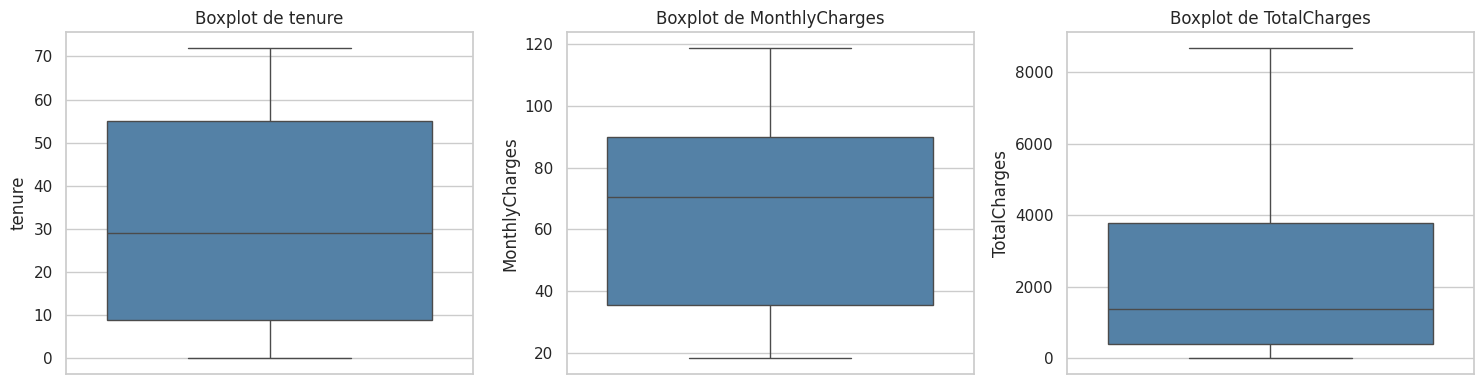

In [4]:
# Detección de Outliers mediante Rango Intercuartílico (IQR)
variables_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']

print("--- Análisis de Outliers (Método IQR) ---")
for col in variables_numericas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    outliers = df[(df[col] < limite_inf) | (df[col] > limite_sup)]
    print(f"{col}: Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f} | Outliers detectados: {len(outliers)}")

# Visualización con Diagramas de Caja (Boxplots)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(variables_numericas):
    sns.boxplot(y=df[col], ax=axes[i], color='steelblue')
    axes[i].set_title(f'Boxplot de {col}')
plt.tight_layout()
plt.show()

**Justificación sobre Valores Atípicos (Outliers):**  
Tanto el cálculo analítico mediante el rango intercuartílico ($1.5 \times IQR$) como la inspección visual de los diagramas de caja (*boxplots*) confirman que **no existen valores atípicos extremos** en ninguna de las tres variables numéricas (`tenure`, `MonthlyCharges` y `TotalCharges`). Todos los valores se encuentran dentro de los límites esperables del negocio, por lo que se conservan el 100% de los registros para el análisis.

## 4. Manipulación y Transformación de Datos con Pandas
En esta sección aplicamos filtros lógicos compuestos (`&`, `|`), transformaciones de columnas e ingeniería de atributos, y segmentación mediante agrupaciones (`groupby`).

In [5]:
# 1. Transformación básica: Renombrado de columna y creación de variables calculadas
# Creamos una copia de trabajo para mantener prolijo el flujo
df_analisis = df.copy()

# Renombramos 'tenure' a 'Antiguedad_Meses' para mayor claridad en reportes
df_analisis.rename(columns={'tenure': 'Antiguedad_Meses'}, inplace=True)

# Creación de columnas calculadas mediante operaciones aritméticas:
# - Diferencia entre el cargo total real y el esperado (Antiguedad * Cargo Mensual)
df_analisis['Diferencia_Facturacion'] = df_analisis['TotalCharges'] - (df_analisis['Antiguedad_Meses'] * df_analisis['MonthlyCharges'])

# - Variable numérica binaria para Churn (1 = Yes, 0 = No) que facilita calcular tasas de cancelación
df_analisis['Churn_Num'] = np.where(df_analisis['Churn'] == 'Yes', 1, 0)

# 2. Filtrado avanzado con múltiples condiciones lógicas (& y |)
# Buscamos clientes de alto riesgo: contrato mes a mes Y (cargo mensual > 80 USD O fibra óptica) con baja antigüedad (<= 6 meses)
clientes_alto_riesgo = df_analisis[
    (df_analisis['Contract'] == 'Month-to-month') &
    ((df_analisis['MonthlyCharges'] > 80) | (df_analisis['InternetService'] == 'Fiber optic')) &
    (df_analisis['Antiguedad_Meses'] <= 6)
]
print(f"Clientes identificados en segmento de alto riesgo: {len(clientes_alto_riesgo)} ({len(clientes_alto_riesgo)/len(df_analisis)*100:.2f}% del total)")

# 3. Agregación y segmentación de negocio mediante groupby
resumen_contrato = df_analisis.groupby('Contract').agg(
    Total_Clientes=('Churn', 'count'),
    Tasa_Churn_Pct=('Churn_Num', lambda x: round(x.mean() * 100, 2)),
    Antiguedad_Promedio=('Antiguedad_Meses', 'mean'),
    Cargo_Mensual_Promedio=('MonthlyCharges', 'mean'),
    Ingresos_Totales=('TotalCharges', 'sum')
).round(2)

print("\n--- Resumen Estadístico por Tipo de Contrato ---")
display(resumen_contrato)

Clientes identificados en segmento de alto riesgo: 619 (8.79% del total)

--- Resumen Estadístico por Tipo de Contrato ---


,Total_Clientes,Tasa_Churn_Pct,Antiguedad_Promedio,Cargo_Mensual_Promedio,Ingresos_Totales
Contract,,,,,
Month-to-month,3875,42.71,18.04,66.40,5305861.5
One year,1473,11.27,42.04,65.05,4467053.5
Two year,1695,2.83,56.74,60.77,6283253.7


## 5. Análisis Exploratorio de Datos (EDA) y Estadística Aplicada

### 5.1 Análisis Cuantitativo y Correlación de Pearson
Calculamos las medidas de tendencia central (media, mediana) y dispersión (desvío estándar, rango intercuartílico, mínimos y máximos) de las variables numéricas principales, junto con su matriz de correlación lineal de Pearson.

In [6]:
# 1. Medidas de tendencia central y dispersión
cols_num = ['tenure', 'MonthlyCharges', 'TotalCharges']
estadisticas = df[cols_num].describe().T
estadisticas['mediana'] = df[cols_num].median()
estadisticas['IQR'] = df[cols_num].quantile(0.75) - df[cols_num].quantile(0.25)

print("--- Medidas de Tendencia Central y Dispersión ---")
display(estadisticas[['count', 'mean', 'mediana', 'std', 'min', '25%', '50%', '75%', 'IQR', 'max']].round(2))

# 2. Matriz de correlación de Pearson
matriz_corr = df[cols_num].corr(method='pearson')
print("\n--- Matriz de Correlación de Pearson ---")
display(matriz_corr.round(4))

--- Medidas de Tendencia Central y Dispersión ---


,count,mean,mediana,std,min,25%,50%,75%,IQR,max
tenure,7043.0,32.37,29.00,24.56,0.00,9.00,29.00,55.00,46.00,72.00
MonthlyCharges,7043.0,64.76,70.35,30.09,18.25,35.50,70.35,89.85,54.35,118.75
TotalCharges,7043.0,2279.73,1394.55,2266.79,0.00,398.55,1394.55,3786.60,3388.05,8684.80



--- Matriz de Correlación de Pearson ---


,tenure,MonthlyCharges,TotalCharges
tenure,1.0000,0.2479,0.8262
MonthlyCharges,0.2479,1.0000,0.6512
TotalCharges,0.8262,0.6512,1.0000


In [7]:
# 3. Análisis Categórico: Frecuencias absolutas, relativas y tablas de contingencia respecto a Churn
print("--- Distribución General de Churn ---")
frec_abs = df['Churn'].value_counts()
frec_rel = df['Churn'].value_counts(normalize=True) * 100
display(pd.DataFrame({'Frecuencia_Absoluta': frec_abs, 'Frecuencia_Relativa_Pct': frec_rel.round(2)}))

# Tablas de contingencia (porcentaje por fila para comparar tasa de abandono)
variables_cat = ['Contract', 'PaymentMethod', 'InternetService', 'SeniorCitizen']

for var in variables_cat:
    print(f"\n--- Tabla de Contingencia (% por fila): {var} vs Churn ---")
    tabla_cont = pd.crosstab(df[var], df['Churn'], normalize='index') * 100
    display(tabla_cont.round(2))

--- Distribución General de Churn ---


,Frecuencia_Absoluta,Frecuencia_Relativa_Pct
Churn,,
No,5174,73.46
Yes,1869,26.54



--- Tabla de Contingencia (% por fila): Contract vs Churn ---


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83



--- Tabla de Contingencia (% por fila): PaymentMethod vs Churn ---


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11



--- Tabla de Contingencia (% por fila): InternetService vs Churn ---


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40



--- Tabla de Contingencia (% por fila): SeniorCitizen vs Churn ---


Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


### 5.2 Visualización de Datos e Interpretación de Negocio
A continuación presentamos el reporte visual del comportamiento de los clientes y los principales impulsores de la cancelación (`Churn`).

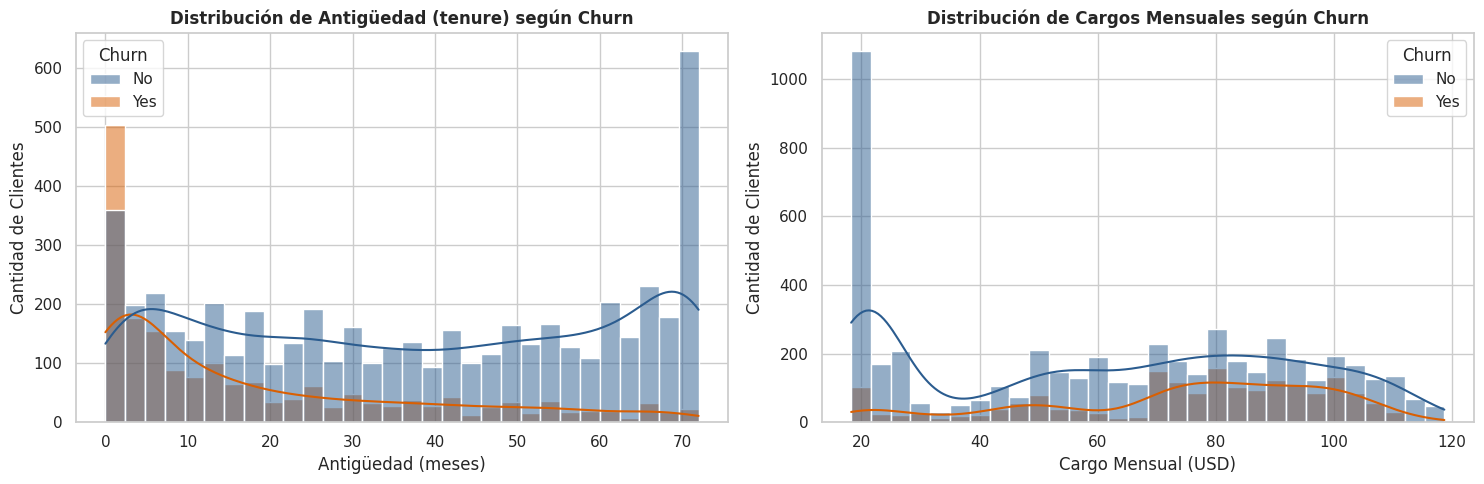

In [8]:
# Gráfico 1: Histogramas y curvas de densidad (KDE) de Antigüedad y Cargos Mensuales
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma + KDE de tenure (Antigüedad)
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=30, palette=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title('Distribución de Antigüedad (tenure) según Churn', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Antigüedad (meses)')
axes[0].set_ylabel('Cantidad de Clientes')

# Histograma + KDE de MonthlyCharges (Cargos Mensuales)
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', kde=True, bins=30, palette=['#2b5c8f', '#d95f02'], ax=axes[1])
axes[1].set_title('Distribución de Cargos Mensuales según Churn', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Cargo Mensual (USD)')
axes[1].set_ylabel('Cantidad de Clientes')

plt.tight_layout()
plt.show()

**Interpretación del Gráfico 1 (Histogramas y KDE):**
* **Antigüedad (`tenure`):** Se observa una distribución bimodal. La mayor concentración de cancelaciones (`Churn = Yes`, en naranja) ocurre durante los **primeros 1 a 5 meses** de relación con la empresa. Una vez que el cliente supera los 24 meses, la tasa de abandono cae drásticamente. *Impacto:* Las acciones de fidelización (onboarding, descuentos iniciales) deben enfocarse en el primer semestre.
* **Cargos Mensuales (`MonthlyCharges`):** Los clientes que abandonan se concentran fuertemente en la franja de tarifas altas (**entre $70 y $105 USD mensuales**), mientras que los planes básicos ($20-$30 USD) presentan altísima retención.

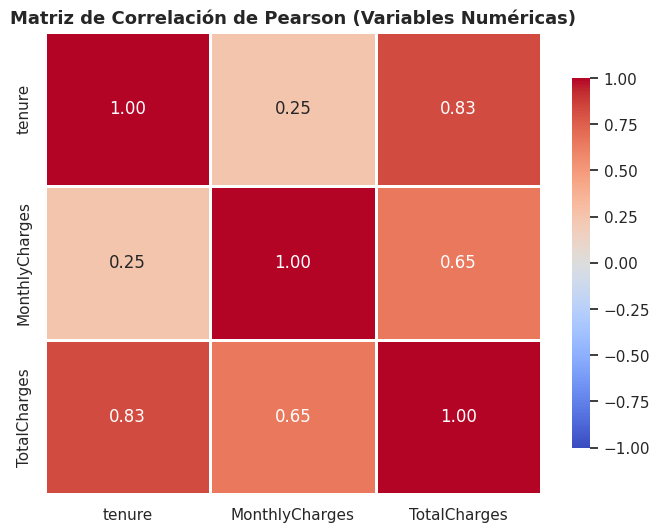

In [9]:
# Gráfico 2: Heatmap de la Matriz de Correlación de Pearson
plt.figure(figsize=(8, 6))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=1,
    cbar_kws={"shrink": 0.8}
)
plt.title('Matriz de Correlación de Pearson (Variables Numéricas)', fontsize=13, fontweight='bold')
plt.show()

**Interpretación del Gráfico 2 (Matriz de Correlación de Pearson):**
* **`tenure` vs. `TotalCharges` ($r = 0.83$):** Correlación lineal **positiva y muy fuerte**. A mayor cantidad de meses de permanencia, mayor es el ingreso acumulado que genera el cliente.
* **`MonthlyCharges` vs. `TotalCharges` ($r = 0.65$):** Correlación **positiva moderada-fuerte**, ya que facturas mensuales más altas incrementan el gasto total acumulado.
* **`tenure` vs. `MonthlyCharges` ($r = 0.25$):** Correlación **positiva débil**. Esto indica que llevar más tiempo en la empresa no implica necesariamente pagar tarifas mucho más altas, lo que explica por qué clientes nuevos con planes caros abandonan rápido sin llegar a generar un alto `TotalCharges`.

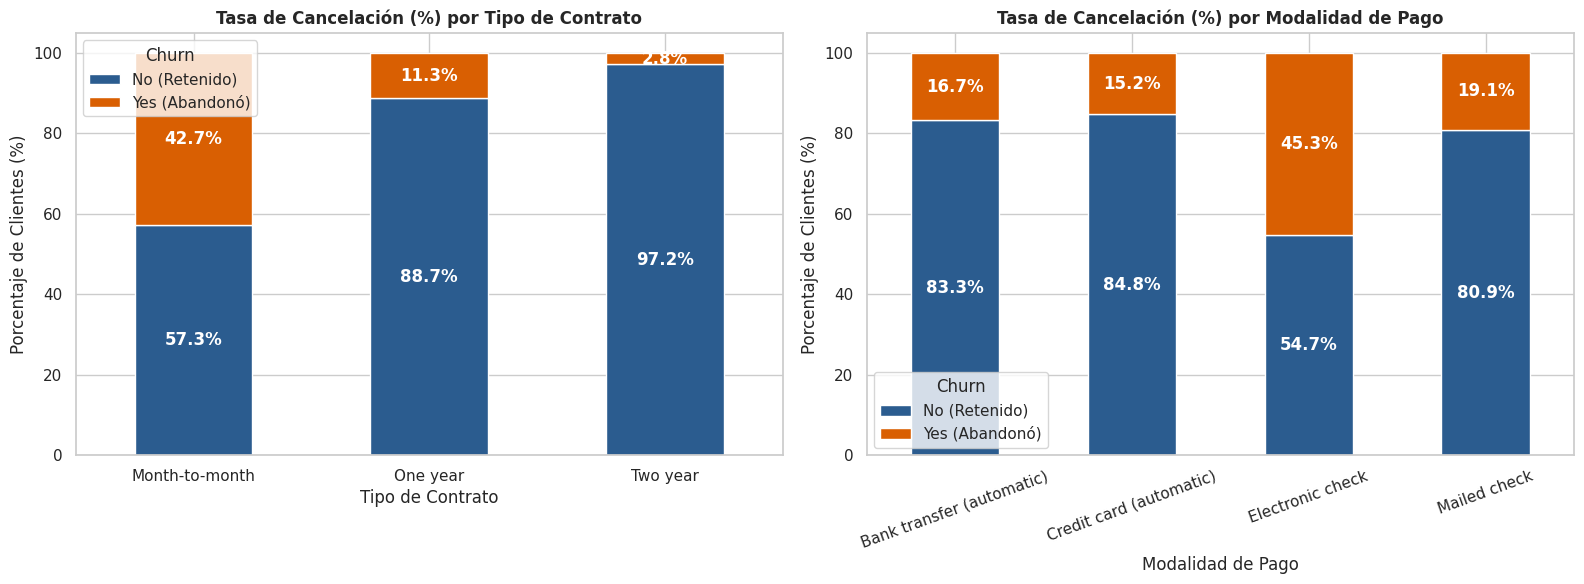

In [10]:
# Gráfico 3: Diagramas de barras comparativos de tasa de Churn por Contrato y Método de Pago
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Tasa de Churn por Tipo de Contrato
contrato_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contrato_churn.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], ax=axes[0], rot=0)
axes[0].set_title('Tasa de Cancelación (%) por Tipo de Contrato', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tipo de Contrato')
axes[0].set_ylabel('Porcentaje de Clientes (%)')
axes[0].legend(title='Churn', labels=['No (Retenido)', 'Yes (Abandonó)'])
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')

# Tasa de Churn por Modalidad de Pago
pago_churn = pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index') * 100
pago_churn.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], ax=axes[1], rot=20)
axes[1].set_title('Tasa de Cancelación (%) por Modalidad de Pago', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Modalidad de Pago')
axes[1].set_ylabel('Porcentaje de Clientes (%)')
axes[1].legend(title='Churn', labels=['No (Retenido)', 'Yes (Abandonó)'])
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Interpretación del Gráfico 3 (Barras Comparativas):**
* **Tipo de Contrato:** El contrato mensual (`Month-to-month`) concentra una tasa de abandono del **42.7%**, frente al **11.3%** del contrato a un año y apenas el **2.8%** del contrato a dos años. La ausencia de compromiso contractual es el principal factor de fuga.
* **Modalidad de Pago:** Quienes pagan mediante cheque electrónico (`Electronic check`) presentan una tasa de cancelación alarmante del **45.3%**, más del doble que los métodos automáticos (transferencia bancaria automática: **16.7%**, tarjeta de crédito automática: **15.2%**). Migrar clientes hacia el débito automático reduce drásticamente el abandono por fricción de pago.

---

## 6. Conclusiones Generales del Análisis
1. **Perfil Crítico de Abandono:** El segmento más vulnerable está compuesto por clientes con **menos de 6 meses de antigüedad**, **contrato mensual**, **cargos superiores a $70 USD** y pago mediante **cheque electrónico**.
2. **Validación de Hipótesis:** Se confirman las tres hipótesis planteadas inicialmente: la modalidad mensual, la baja antigüedad y las tarifas mensuales elevadas impulsan significativamente el *Churn*.
3. **Recomendaciones Estratégicas:** Implementar incentivos de migración de contratos mensuales a planes anuales durante los primeros 3 meses y ofrecer bonificaciones por adhesión al débito automático.